In [81]:

import sys
from pathlib import Path

# Find the project root automatically
current_dir = Path.cwd().resolve()

project_root = next(
    (
        path for path in (current_dir, *current_dir.parents)
        if (path / "src" / "utils.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        f"Project root not found from {current_dir}. "
        "Open the MMM project folder in VS Code."
    )

# Add project root to Python's import path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Project path configured successfully!")


Project root: D:\Internship Tasks\Group Task - Marketing Mix Modelling (MMM) & Budget Optimisation\mmm-budget-optimization
Project path configured successfully!


In [82]:

import pandas as pd
import numpy as np

from src.utils import DATA_PROCESSED, load_params

# Load the existing project configuration
params = load_params()

# Load the previous subgroup's feature-engineered dataset
data_path = DATA_PROCESSED / "feature_engineered_marketing_mix_data.csv"

df = pd.read_csv(data_path, parse_dates=["month"])

# Sort chronologically (important for Adstock)
df = df.sort_values("month").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("First month:", df["month"].min())
print("Last month:", df["month"].max())

display(df.head())


Dataset shape: (36, 44)
First month: 2023-01-01 00:00:00
Last month: 2025-12-01 00:00:00


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


In [83]:

# Read channel names and target from existing config
channels = params["channels"]
target = params["target"]

print("Marketing Channels:")
for i, channel in enumerate(channels, start=1):
    print(f"{i}. {channel}")

print("\nTarget variable:", target)

# Display advertising spend and sales
display(df[["month"] + channels + [target]].head())


Marketing Channels:
1. tv_spend_lkr
2. facebook_instagram_spend_lkr
3. google_search_spend_lkr
4. youtube_spend_lkr
5. radio_spend_lkr
6. outdoor_spend_lkr

Target variable: sales_revenue_lkr


,month,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,sales_revenue_lkr
0,2023-01-01,4274762,3890003,2467793,1836858,1700676,1813444,7.011407e+07
1,2023-02-01,4023574,5062635,2962576,2254198,1922384,2941194,7.359455e+07
2,2023-03-01,5359091,3746337,4080535,2363737,1720670,2063917,8.506329e+07
3,2023-04-01,5102550,3690115,3390558,2595121,1217450,3091430,1.000579e+08
4,2023-05-01,4972723,5333813,3240078,2343364,1568285,3525300,7.750229e+07


In [84]:

# Basic validation checks
print("Missing values:", df.isnull().sum().sum())
print("Duplicate months:", df["month"].duplicated().sum())

# Check for missing months
expected_months = pd.date_range(
    start=df["month"].min(),
    end=df["month"].max(),
    freq="MS"
)

missing_months = expected_months.difference(df["month"])
print("Missing months:", len(missing_months))

# Check for negative advertising spend
negative_spend = (df[channels] < 0).sum().sum()
print("Negative spend values:", negative_spend)

# Check our main required columns
required_columns = ["month"] + channels + [target]
print(
    "Required columns available:",
    all(col in df.columns for col in required_columns)
)


Missing values: 0
Duplicate months: 0
Missing months: 0
Negative spend values: 0
Required columns available: True


In [85]:

from src.transforms import geometric_adstock

# Small example to test the existing function
spend = np.array([100, 0, 0])

result = geometric_adstock(spend, decay=0.4)

print("Original spend:", spend)
print("Adstock result:", result)


Original spend: [100   0   0]
Adstock result: [100.  40.  16.]


## Step 3: Geometric Adstock Transformation

In [86]:

import importlib
import src.transforms as transforms

# Reload the updated Python module
importlib.reload(transforms)

# Update the notebook's function reference
geometric_adstock = transforms.geometric_adstock

print("Updated Adstock function loaded successfully!")


Updated Adstock function loaded successfully!


In [87]:

from src.transforms import geometric_adstock

# Test 1: Advertising carryover
test_spend = np.array([100, 0, 0, 0], dtype=float)

test_result = geometric_adstock(test_spend, decay=0.4)

expected = np.array([100, 40, 16, 6.4])

np.testing.assert_allclose(test_result, expected)

# Test 2: Zero decay means no carryover
zero_decay = geometric_adstock(test_spend, decay=0.0)

np.testing.assert_allclose(zero_decay, test_spend)

# Test 3: Invalid decay must be rejected
try:
    geometric_adstock(test_spend, decay=1.5)
except ValueError:
    pass
else:
    raise AssertionError("Invalid decay was not rejected.")

print("All Adstock tests passed!")
print("Test result:", test_result)


All Adstock tests passed!
Test result: [100.   40.   16.    6.4]


In [88]:

# Get channel names and decay parameters from config
channels = params["channels"]
decay_rates = params["adstock_decay"]

# Keep transformed features separate from source dataset
adstock_df = df[["month"]].copy()

# Apply geometric adstock for all six channels
for channel in channels:

    decay = decay_rates[channel]

    # Example: tv_spend_lkr -> tv_adstock_lkr
    output_name = (
        channel.removesuffix("_spend_lkr") + "_adstock_lkr"
    )

    adstock_df[output_name] = geometric_adstock(
        df[channel].to_numpy(dtype=float),
        decay=decay
    )

    print(f"{channel}: decay = {decay}")

print("\nAdstock transformations completed!")
print("Output shape:", adstock_df.shape)

display(adstock_df.head())


tv_spend_lkr: decay = 0.4
facebook_instagram_spend_lkr: decay = 0.2
google_search_spend_lkr: decay = 0.1
youtube_spend_lkr: decay = 0.3
radio_spend_lkr: decay = 0.2
outdoor_spend_lkr: decay = 0.3

Adstock transformations completed!
Output shape: (36, 7)


,month,tv_adstock_lkr,facebook_instagram_adstock_lkr,google_search_adstock_lkr,youtube_adstock_lkr,radio_adstock_lkr,outdoor_adstock_lkr
0,2023-01-01,4.274762e+06,3.890003e+06,2.467793e+06,1.836858e+06,1.700676e+06,1.813444e+06
1,2023-02-01,5.733479e+06,5.840636e+06,3.209355e+06,2.805255e+06,2.262519e+06,3.485227e+06
2,2023-03-01,7.652483e+06,4.914464e+06,4.401471e+06,3.205314e+06,2.173174e+06,3.109485e+06
3,2023-04-01,8.163543e+06,4.673008e+06,3.830705e+06,3.556715e+06,1.652085e+06,4.024276e+06
4,2023-05-01,8.238140e+06,6.268415e+06,3.623149e+06,3.410379e+06,1.898702e+06,4.732583e+06


In [89]:

assert len(adstock_df) == len(df)
assert adstock_df.shape[1] == 7

for channel in channels:
    name = channel.removesuffix("_spend_lkr") + "_adstock_lkr"

    raw_spend = df[channel].to_numpy(dtype=float)
    transformed = adstock_df[name].to_numpy()

    # No missing or infinite outputs
    assert np.isfinite(transformed).all()

    # Nonnegative spend with nonnegative decay
    assert np.all(transformed >= raw_spend - 1e-8)

    # First month assumes zero earlier carryover
    np.testing.assert_allclose(
        transformed[0], raw_spend[0]
    )

# Known value check using actual January/February TV spend
np.testing.assert_allclose(
    adstock_df.loc[1, "tv_adstock_lkr"],
    5733478.8
)

print("All six Adstock channels validated successfully!")


All six Adstock channels validated successfully!


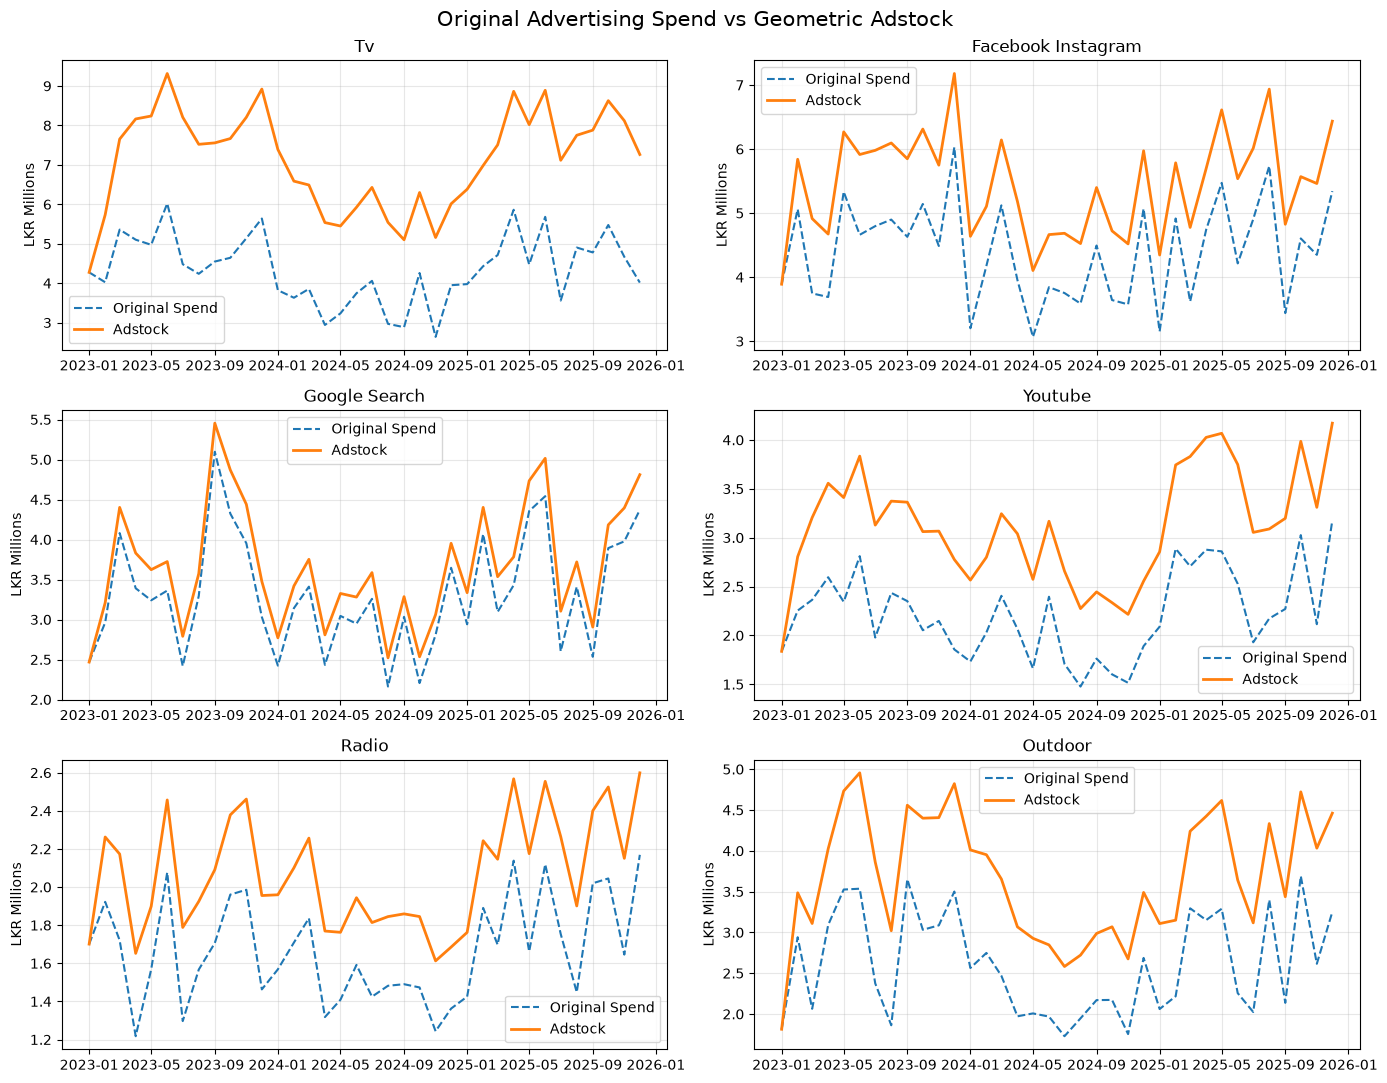

In [90]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, channel in enumerate(channels):

    ax = axes[i]

    adstock_col = (
        channel.removesuffix("_spend_lkr") + "_adstock_lkr"
    )

    # Convert LKR to millions for readability
    original = df[channel] / 1_000_000
    transformed = adstock_df[adstock_col] / 1_000_000

    ax.plot(
        df["month"],
        original,
        label="Original Spend",
        linestyle="--"
    )

    ax.plot(
        df["month"],
        transformed,
        label="Adstock",
        linewidth=2
    )

    ax.set_title(channel.replace("_spend_lkr", "").replace("_", " ").title())
    ax.set_ylabel("LKR Millions")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Original Advertising Spend vs Geometric Adstock",
    fontsize=15
)

plt.tight_layout()
plt.show()


## Step 4: Hill Saturation Transformation

In [91]:

import importlib
import src.transforms as transforms

# Reload updated Python module
importlib.reload(transforms)

hill_saturation = transforms.hill_saturation
transform_channel = transforms.transform_channel

print("Hill Saturation function loaded successfully!")


Hill Saturation function loaded successfully!


In [92]:

# Test 1: Basic Hill saturation
test_x = np.array([0, 100, 200], dtype=float)

result = hill_saturation(
    test_x,
    half_sat=100,
    slope=1.0
)

expected = np.array([0, 0.5, 2/3])

np.testing.assert_allclose(result, expected)

# Test 2: Changing the slope
result_slope2 = hill_saturation(
    test_x,
    half_sat=100,
    slope=2.0
)

np.testing.assert_allclose(
    result_slope2,
    [0, 0.5, 0.8]
)

# Test 3: Reject invalid parameters
invalid_cases = [
    (np.array([100.0]), 0, 1.0),
    (np.array([100.0]), 100, 0),
    (np.array([-50.0]), 100, 1.0),
    (np.array([100.0]), None, 1.0)
]

for x, k, s in invalid_cases:
    try:
        hill_saturation(x, half_sat=k, slope=s)
    except ValueError:
        pass
    else:
        raise AssertionError(
            f"Invalid input was accepted: K={k}, s={s}"
        )

print("All Hill Saturation tests passed!")
print("Example result:", result)


All Hill Saturation tests passed!
Example result: [0.         0.5        0.66666667]


In [93]:

# Chronological training split
test_months = int(params["test_size_months"])
train_size = len(df) - test_months

print("Training months:", train_size)
print("Test months:", test_months)

# Compute provisional K using training data only
half_sat_params = {}

for channel in channels:

    adstock_col = (
        channel.removesuffix("_spend_lkr")
        + "_adstock_lkr"
    )

    train_values = adstock_df[
        adstock_col
    ].iloc[:train_size].to_numpy(dtype=float)

    # Only use positive training Adstock values
    positive_values = train_values[train_values > 0]

    if len(positive_values) == 0:
        raise ValueError(
            f"No positive Adstock values for {channel}"
        )

    k = float(np.median(positive_values))

    half_sat_params[channel] = k

    print(f"{channel}: K = {k:,.2f} LKR")


Training months: 30
Test months: 6
tv_spend_lkr: K = 7,186,472.04 LKR
facebook_instagram_spend_lkr: K = 5,468,062.35 LKR
google_search_spend_lkr: K = 3,554,542.30 LKR
youtube_spend_lkr: K = 3,064,299.31 LKR
radio_spend_lkr: K = 1,949,688.51 LKR
outdoor_spend_lkr: K = 3,565,589.84 LKR


In [94]:

# Keep saturation features separate
saturation_df = df[["month"]].copy()

for channel in channels:

    base = channel.removesuffix("_spend_lkr")

    adstock_col = f"{base}_adstock_lkr"
    saturation_col = f"{base}_saturated"

    # Preliminary half-saturation
    k = half_sat_params[channel]

    # Slope from existing configuration
    slope = params["saturation"][channel]["slope"]

    saturation_df[saturation_col] = hill_saturation(
        adstock_df[adstock_col].to_numpy(dtype=float),
        half_sat=k,
        slope=slope
    )

    print(f"{channel}: K={k:,.2f}, slope={slope}")

print("\nHill Saturation completed!")
print("Output shape:", saturation_df.shape)

display(saturation_df.head())


tv_spend_lkr: K=7,186,472.04, slope=1.0
facebook_instagram_spend_lkr: K=5,468,062.35, slope=1.0
google_search_spend_lkr: K=3,554,542.30, slope=1.0
youtube_spend_lkr: K=3,064,299.31, slope=1.0
radio_spend_lkr: K=1,949,688.51, slope=1.0
outdoor_spend_lkr: K=3,565,589.84, slope=1.0

Hill Saturation completed!
Output shape: (36, 7)


,month,tv_saturated,facebook_instagram_saturated,google_search_saturated,youtube_saturated,radio_saturated,outdoor_saturated
0,2023-01-01,0.372976,0.415685,0.409773,0.374780,0.465892,0.337132
1,2023-02-01,0.443769,0.516473,0.474483,0.477933,0.537134,0.494301
2,2023-03-01,0.515702,0.473340,0.553226,0.511246,0.527103,0.465835
3,2023-04-01,0.531826,0.460800,0.518697,0.537186,0.458686,0.530217
4,2023-05-01,0.534091,0.534097,0.504779,0.526726,0.493376,0.570316


In [95]:

# Verify dimensions
assert len(saturation_df) == len(df)
assert saturation_df.shape[1] == 7

# Verify every channel
for channel in channels:

    base = channel.removesuffix("_spend_lkr")
    sat_col = f"{base}_saturated"

    values = saturation_df[sat_col].to_numpy()

    # No missing or infinite values
    assert np.isfinite(values).all()

    # Saturation should be between 0 and 1
    assert np.all(values >= 0)
    assert np.all(values <= 1)

    # Check combined function matches separate steps
    combined = transform_channel(
        df[channel].to_numpy(dtype=float),
        decay=params["adstock_decay"][channel],
        half_sat=half_sat_params[channel],
        slope=params["saturation"][channel]["slope"]
    )

    np.testing.assert_allclose(
        combined,
        values,
        rtol=1e-10
    )

print("All six Saturation channels validated!")
print("Combined Adstock + Saturation test passed!")


All six Saturation channels validated!
Combined Adstock + Saturation test passed!


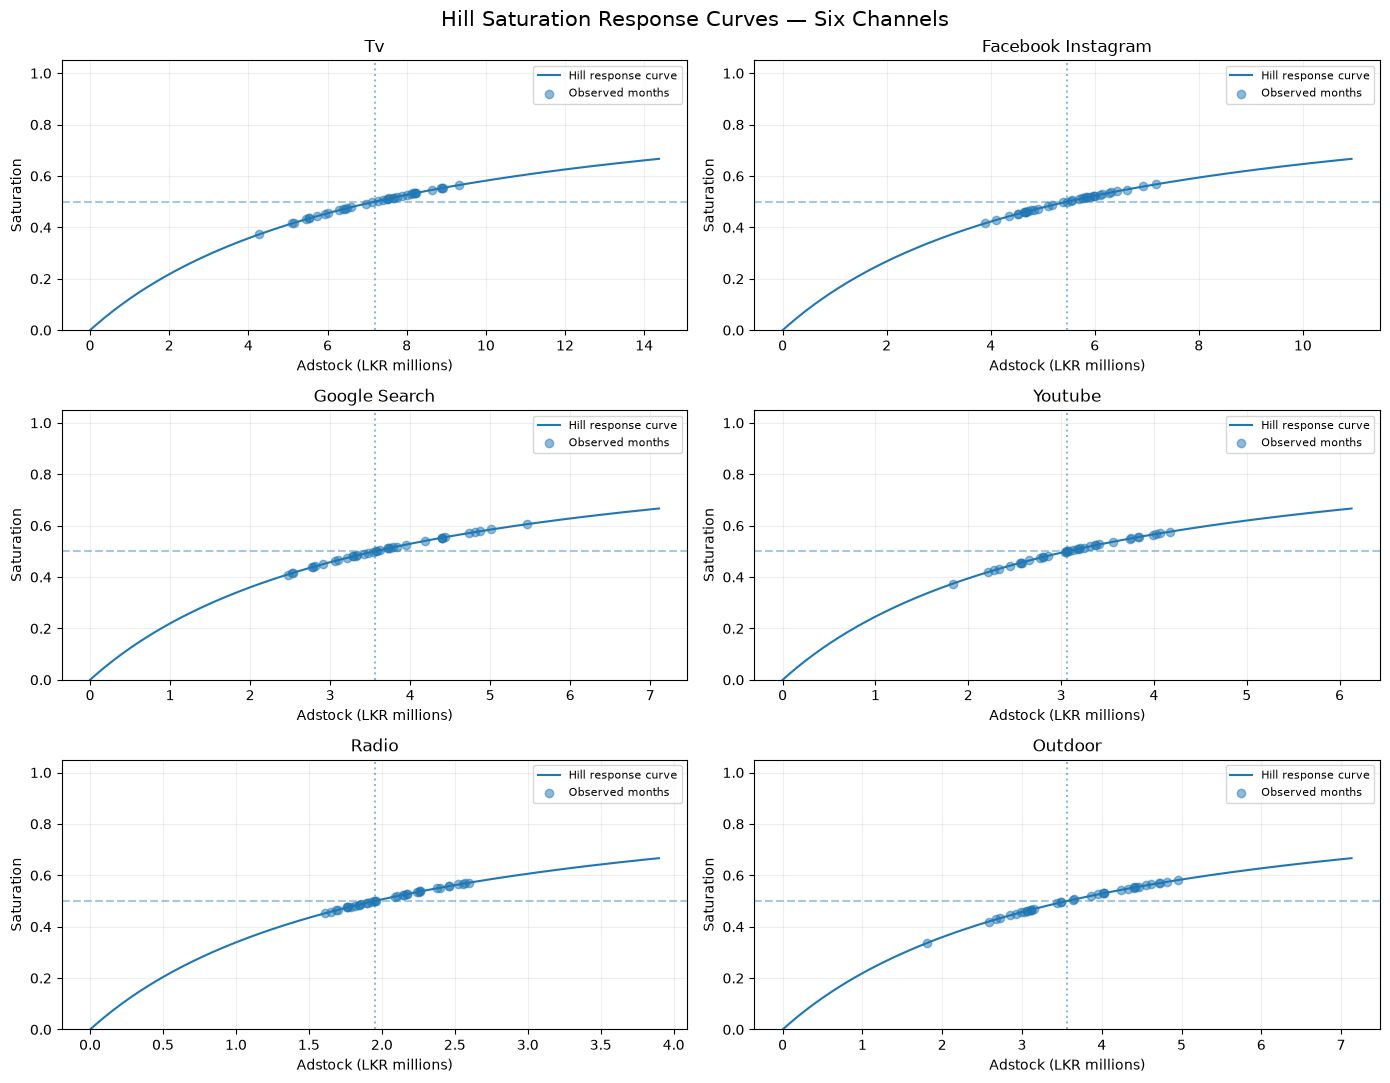

In [96]:

import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, channel in enumerate(channels):

    ax = axes[i]
    base = channel.removesuffix("_spend_lkr")

    adstock_col = f"{base}_adstock_lkr"
    sat_col = f"{base}_saturated"

    k = half_sat_params[channel]
    slope = params["saturation"][channel]["slope"]

    observed_x = adstock_df[adstock_col].to_numpy()

    # Continuous curve for visualization
    x_max = max(observed_x.max() * 1.2, 2 * k)
    x_grid = np.linspace(0, x_max, 200)

    y_grid = hill_saturation(
        x_grid, half_sat=k, slope=slope
    )

    ax.plot(
        x_grid / 1_000_000,
        y_grid,
        label="Hill response curve"
    )

    ax.scatter(
        observed_x / 1_000_000,
        saturation_df[sat_col],
        alpha=0.5,
        label="Observed months"
    )

    ax.axhline(0.5, linestyle="--", alpha=0.4)
    ax.axvline(k / 1_000_000, linestyle=":", alpha=0.5)

    ax.set_title(base.replace("_", " ").title())
    ax.set_xlabel("Adstock (LKR millions)")
    ax.set_ylabel("Saturation")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

plt.suptitle(
    "Hill Saturation Response Curves — Six Channels",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [97]:

import importlib
import src.transforms as transforms

importlib.reload(transforms)

transform_channel_with_training_k = (
    transforms.transform_channel_with_training_k
)

print("Parameter transformation helper loaded!")


Parameter transformation helper loaded!


In [98]:

# Use the approved chronological training period
test_months = int(params["test_size_months"])
train_end = len(df) - test_months

assert test_months == 6
assert train_end == 30

train_df = df.iloc[:train_end].copy()

decay_offsets = [-0.1, 0.0, 0.1]
k_multipliers = [0.75, 1.0, 1.25]

candidate_rows = []

for channel in channels:

    base_decay = float(params["adstock_decay"][channel])
    slope = float(params["saturation"][channel]["slope"])

    for offset in decay_offsets:

        decay = round(base_decay + offset, 2)

        if not (0 <= decay < 1):
            continue

        for multiplier in k_multipliers:

            saturated, k = transform_channel_with_training_k(
                x=train_df[channel].to_numpy(dtype=float),
                decay=decay,
                train_end=len(train_df),
                k_multiplier=multiplier,
                slope=slope
            )

            assert np.isfinite(saturated).all()

            is_baseline = (
                np.isclose(decay, base_decay)
                and np.isclose(multiplier, 1.0)
            )

            candidate_rows.append({
                "channel": channel,
                "decay": decay,
                "k_multiplier": multiplier,
                "half_sat_lkr": k,
                "slope": slope,
                "variant": (
                    "baseline" if is_baseline else "alternative"
                )
            })

candidate_df = pd.DataFrame(candidate_rows)

print("Total candidate rows:", len(candidate_df))
display(candidate_df.head(12))


Total candidate rows: 54


,channel,decay,k_multiplier,half_sat_lkr,slope,variant
0,tv_spend_lkr,0.3,0.75,4.593059e+06,1.0,alternative
1,tv_spend_lkr,0.3,1.00,6.124078e+06,1.0,alternative
2,tv_spend_lkr,0.3,1.25,7.655098e+06,1.0,alternative
3,tv_spend_lkr,0.4,0.75,5.389854e+06,1.0,alternative
4,tv_spend_lkr,0.4,1.00,7.186472e+06,1.0,baseline
5,tv_spend_lkr,0.4,1.25,8.983090e+06,1.0,alternative
6,tv_spend_lkr,0.5,0.75,6.239024e+06,1.0,alternative
7,tv_spend_lkr,0.5,1.00,8.318699e+06,1.0,alternative
8,tv_spend_lkr,0.5,1.25,1.039837e+07,1.0,alternative
9,facebook_instagram_spend_lkr,0.1,0.75,3.640550e+06,1.0,alternative


In [99]:

baseline_df = candidate_df[
    candidate_df["variant"] == "baseline"
].copy()

display(
    baseline_df[
        ["channel", "decay", "half_sat_lkr", "slope"]
    ].round(2)
)


,channel,decay,half_sat_lkr,slope
4,tv_spend_lkr,0.4,7186472.04,1.0
13,facebook_instagram_spend_lkr,0.2,5468062.35,1.0
22,google_search_spend_lkr,0.1,3554542.30,1.0
31,youtube_spend_lkr,0.3,3064299.31,1.0
40,radio_spend_lkr,0.2,1949688.51,1.0
49,outdoor_spend_lkr,0.3,3565589.84,1.0


In [100]:

# Test the baseline configuration for each channel
for channel in channels:

    base = channel.removesuffix("_spend_lkr")
    sat_col = f"{base}_saturated"

    result, k = transform_channel_with_training_k(
        x=df[channel].to_numpy(dtype=float),
        decay=params["adstock_decay"][channel],
        train_end=train_end,
        k_multiplier=1.0,
        slope=params["saturation"][channel]["slope"]
    )

    # Compare with Step 4 results
    np.testing.assert_allclose(
        result,
        saturation_df[sat_col].to_numpy(dtype=float),
        rtol=1e-10
    )

    # Test-period changes must not affect estimated K
    modified_spend = df[channel].to_numpy(dtype=float).copy()
    modified_spend[train_end:] *= 1.5

    _, k_modified = transform_channel_with_training_k(
        x=modified_spend,
        decay=params["adstock_decay"][channel],
        train_end=train_end,
        k_multiplier=1.0,
        slope=params["saturation"][channel]["slope"]
    )

    np.testing.assert_allclose(k, k_modified)

print("All six baseline transformations match Step 4!")
print("Training-only K calculation verified!")


All six baseline transformations match Step 4!
Training-only K calculation verified!


In [101]:

import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import DATA_PROCESSED, FIGURES, load_params
import src.transforms as transforms

# Reload latest local transformation code
importlib.reload(transforms)

# Confirm our Step 3-5 functions exist
required_functions = [
    "geometric_adstock",
    "hill_saturation",
    "transform_channel",
    "transform_channel_with_training_k"
]

for function_name in required_functions:
    assert hasattr(transforms, function_name), (
        f"Missing function: {function_name}"
    )

# Reload configuration and data
params = load_params()
channels = params["channels"]
target = params["target"]

data_path = (
    DATA_PROCESSED /
    "feature_engineered_marketing_mix_data.csv"
)

df = pd.read_csv(
    data_path,
    parse_dates=["month"]
)

df = df.sort_values("month").reset_index(drop=True)

test_months = int(params["test_size_months"])
train_end = len(df) - test_months

# Verify basic structure
assert df.shape == (36, 44)
assert train_end == 30
assert test_months == 6
assert df["month"].is_unique

expected_months = pd.date_range(
    df["month"].min(),
    df["month"].max(),
    freq="MS"
)

assert df["month"].tolist() == list(expected_months)
assert df[channels].notna().all().all()
assert (df[channels] >= 0).all().all()

print("All transformation functions available!")
print("Dataset validation passed!")
print("Training months:", train_end)
print("Testing months:", test_months)


All transformation functions available!
Dataset validation passed!
Training months: 30
Testing months: 6


In [102]:

# Generate baseline transformed media features
media_features = df[["month"]].copy()

parameter_records = []

for channel in channels:

    base = channel.removesuffix("_spend_lkr")
    feature_name = f"{base}_saturated"

    decay = float(params["adstock_decay"][channel])
    slope = float(params["saturation"][channel]["slope"])

    # Estimate K using training months only
    saturated, half_sat = (
        transforms.transform_channel_with_training_k(
            x=df[channel].to_numpy(dtype=float),
            decay=decay,
            train_end=train_end,
            k_multiplier=1.0,
            slope=slope
        )
    )

    media_features[feature_name] = saturated

    parameter_records.append({
        "channel": channel,
        "decay": decay,
        "half_sat_lkr": half_sat,
        "slope": slope
    })

parameter_snapshot = pd.DataFrame(parameter_records)

feature_cols = [
    ch.removesuffix("_spend_lkr") + "_saturated"
    for ch in channels
]

print("Media feature shape:", media_features.shape)

display(media_features.head())
display(parameter_snapshot.round(2))


Media feature shape: (36, 7)


,month,tv_saturated,facebook_instagram_saturated,google_search_saturated,youtube_saturated,radio_saturated,outdoor_saturated
0,2023-01-01,0.372976,0.415685,0.409773,0.374780,0.465892,0.337132
1,2023-02-01,0.443769,0.516473,0.474483,0.477933,0.537134,0.494301
2,2023-03-01,0.515702,0.473340,0.553226,0.511246,0.527103,0.465835
3,2023-04-01,0.531826,0.460800,0.518697,0.537186,0.458686,0.530217
4,2023-05-01,0.534091,0.534097,0.504779,0.526726,0.493376,0.570316


,channel,decay,half_sat_lkr,slope
0,tv_spend_lkr,0.4,7186472.04,1.0
1,facebook_instagram_spend_lkr,0.2,5468062.35,1.0
2,google_search_spend_lkr,0.1,3554542.30,1.0
3,youtube_spend_lkr,0.3,3064299.31,1.0
4,radio_spend_lkr,0.2,1949688.51,1.0
5,outdoor_spend_lkr,0.3,3565589.84,1.0


In [103]:

# Verify all media features
assert media_features.shape == (36, 7)
assert media_features["month"].equals(df["month"])

for channel in channels:

    base = channel.removesuffix("_spend_lkr")
    feature_name = f"{base}_saturated"

    x = df[channel].to_numpy(dtype=float)

    decay = float(params["adstock_decay"][channel])
    slope = float(params["saturation"][channel]["slope"])

    # Recalculate training-only K
    result, k = (
        transforms.transform_channel_with_training_k(
            x=x,
            decay=decay,
            train_end=train_end,
            k_multiplier=1.0,
            slope=slope
        )
    )

    observed = media_features[
        feature_name
    ].to_numpy(dtype=float)

    # Check 1: Output values are finite
    assert np.isfinite(observed).all()

    # Check 2: All saturation values in [0, 1]
    assert ((observed >= 0) & (observed <= 1)).all()

    # Check 3: Compare against independent composition
    adstock = transforms.geometric_adstock(x, decay)

    expected = transforms.hill_saturation(
        adstock,
        half_sat=k,
        slope=slope
    )

    np.testing.assert_allclose(
        observed,
        expected,
        rtol=1e-10
    )

    # Check 4: Each feature varies during training
    assert np.std(observed[:train_end]) > 0

    # Check 5: Adstock continues across train/test boundary
    np.testing.assert_allclose(
        adstock[train_end],
        x[train_end] + decay * adstock[train_end - 1]
    )

    # Check 6: Test-period spending cannot alter K
    changed_x = x.copy()
    changed_x[train_end:] *= 2

    changed_result, changed_k = (
        transforms.transform_channel_with_training_k(
            x=changed_x,
            decay=decay,
            train_end=train_end,
            k_multiplier=1.0,
            slope=slope
        )
    )

    np.testing.assert_allclose(k, changed_k)

    np.testing.assert_allclose(
        observed[:train_end],
        changed_result[:train_end]
    )

    print(f"PASS: {channel}")

print("\nAll six media transformations passed!")
print("Training-only parameter checks passed!")


PASS: tv_spend_lkr
PASS: facebook_instagram_spend_lkr
PASS: google_search_spend_lkr
PASS: youtube_spend_lkr
PASS: radio_spend_lkr
PASS: outdoor_spend_lkr

All six media transformations passed!
Training-only parameter checks passed!


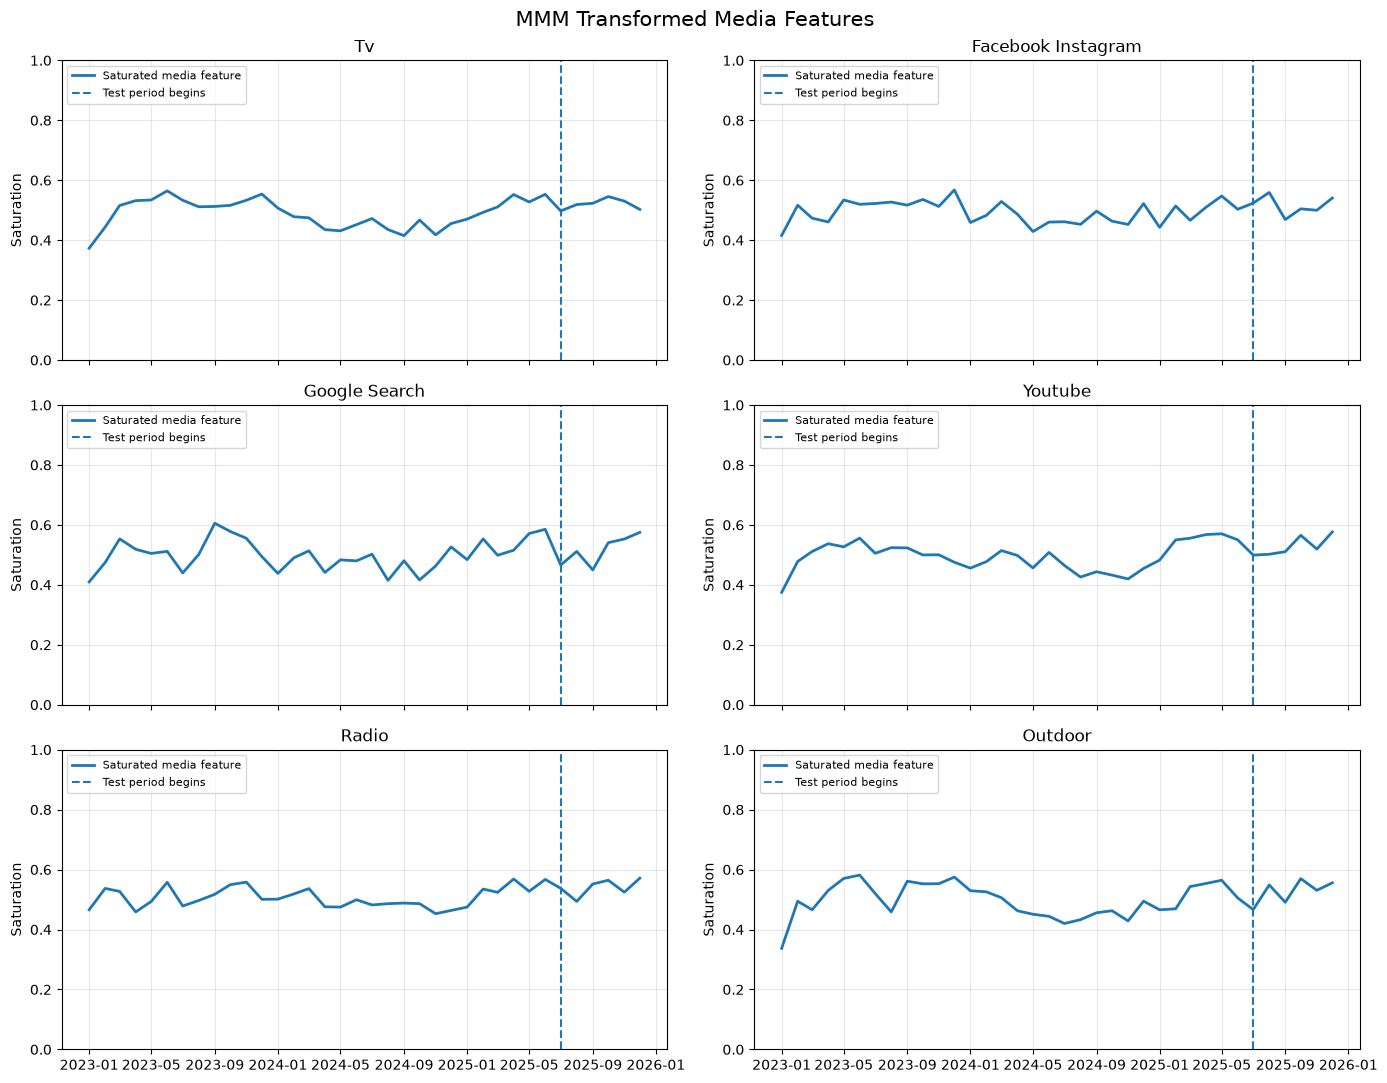

Figure saved: D:\Internship Tasks\Group Task - Marketing Mix Modelling (MMM) & Budget Optimisation\mmm-budget-optimization\outputs\figures\mmm_media_saturation_timeseries.png


In [104]:

FIGURES.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    3, 2, figsize=(14, 11), sharex=True
)

axes = axes.flatten()

for i, channel in enumerate(channels):

    ax = axes[i]

    base = channel.removesuffix("_spend_lkr")
    feature_name = f"{base}_saturated"

    ax.plot(
        media_features["month"],
        media_features[feature_name],
        linewidth=2,
        label="Saturated media feature"
    )

    # Show held-out test period
    ax.axvline(
        df["month"].iloc[train_end],
        linestyle="--",
        label="Test period begins"
    )

    ax.set_title(base.replace("_", " ").title())
    ax.set_ylabel("Saturation")
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(
    "MMM Transformed Media Features",
    fontsize=15
)

plt.tight_layout()

# Save using existing project output folder
plot_path = (
    FIGURES / "mmm_media_saturation_timeseries.png"
)

plt.savefig(
    plot_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", plot_path)


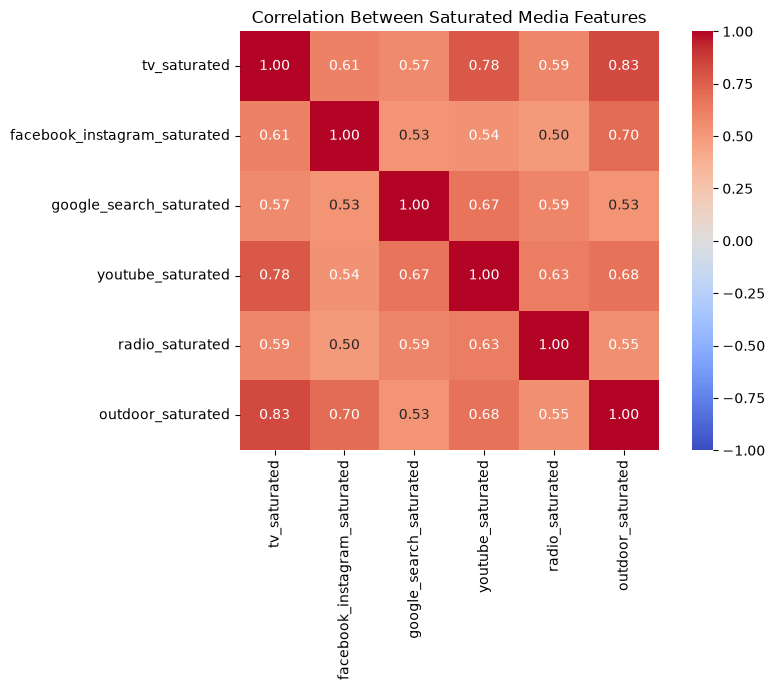

No feature pairs above absolute correlation 0.85.
Correlation analysis complete!


In [105]:

import seaborn as sns

train_media = media_features[
    feature_cols
].iloc[:train_end]

correlation_matrix = train_media.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Correlation Between Saturated Media Features")
plt.tight_layout()

corr_path = (
    FIGURES / "mmm_media_feature_correlations.png"
)

plt.savefig(
    corr_path,
    dpi=160,
    bbox_inches="tight"
)

plt.show()

# Identify potentially strong correlations
high_corr_pairs = []

for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):

        value = correlation_matrix.iloc[i, j]

        if abs(value) > 0.85:
            high_corr_pairs.append(
                (feature_cols[i], feature_cols[j], value)
            )

if high_corr_pairs:
    print("Potentially high feature correlations:")
    for a, b, value in high_corr_pairs:
        print(f"{a} vs {b}: {value:.3f}")
else:
    print("No feature pairs above absolute correlation 0.85.")

print("Correlation analysis complete!")
